# 2D Hessian follow-up: gradient error, availability and aggregation
November 19, 2026 | NumPy/sklearn/Matplotlib | reproducible exploratory experiments

**Research questions:** (1) Does the empirical spacing and location adjustment work beyond the balanced grid? (2) Which terms cause its failure? (3) How often does a tree expose usable direct comparisons or corrected mixed comparisons? (4) Does pooling help? (5) Does increasing sample size while considering box size improve accuracy?

This is a separate experiment, not a replacement of the original estimator. Retain Nathan's Nov 16 scope: known noiseless 2D quadratic, real fitted CART regions, multiple estimates. No 3D, no least squares, no new physics loss. The true Hessian is never an input to the candidate estimators; used only for diagnostics and evaluation. The original exact continuous-box mean is an oracle control in the companion notebook.

## 1. Setup and original helper functions

**Why:** Reuse the original quadratic and geometric formulas, so comparison is controlled.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor
from itertools import combinations
H_true = np.array([[4.,1.5],[1.5,3.]])
def f(x1,x2):
    return .7-x1+2*x2+2*x1**2+1.5*x1*x2+1.5*x2**2
grid = np.linspace(0,1,11)
X = np.array([(x1,x2) for x1 in grid for x2 in grid])
y = f(*X.T)
def fit_tree(depth, X=X, y=y):
    return DecisionTreeRegressor(max_depth=depth, min_samples_leaf=4, random_state=0).fit(X,y)

def get_width(l1, u1, l2, u2, axis):
    if axis == 0:
        return u1 - l1
    elif axis == 1:
        return u2 - l2
    raise ValueError('Invalid split axis')


def gradient_estimate(mean_left, mean_right, width):
    return 2*(mean_right - mean_left)/width


def effective_location(l1, u1, l2, u2, tau, axis):
    if axis == 0:
        m1 = (l1 + tau + u1)/3
        m2 = (l2 + u2)/2
    elif axis == 1:
        m1 = (l1 + u1)/2
        m2 = (l2 + tau + u2)/3
    else:
        raise ValueError('Invalid split axis')
    return np.array([m1, m2])
def node_info(tree, path=''):
    t = tree.tree_
    node = 0
    bounds = [0.,1.,0.,1.]
    for side in path:
        axis,tau = t.feature[node],t.threshold[node]
        if axis < 0 or side not in ('L','R'):
            raise ValueError('Invalid node path')
        if side == 'L':
            bounds[2*axis+1] = tau
            node = t.children_left[node]
        else:
            bounds[2*axis] = tau
            node = t.children_right[node]
    axis,tau = t.feature[node],t.threshold[node]
    v = dict(path=path,id=node,axis=axis,tau=tau,bounds=bounds,
             n=t.n_node_samples[node],mean=t.value[node].item())
    if axis >= 0:
        ml = t.value[t.children_left[node]].item()
        mr = t.value[t.children_right[node]].item()
        width = get_width(*bounds,axis)
        v.update(mean_left=ml,mean_right=mr,width=width,
                 g=gradient_estimate(ml,mr,width),
                 m=effective_location(*bounds,tau,axis))
    return v

def node_gradient(tree,path,expected_axis):
    v = node_info(tree,path)
    assert v['axis'] == expected_axis, 'Unexpected splitting axis'
    return v['g'],v['m']


def internal_nodes(tree):
    nodes = {}
    def visit(path):
        v = node_info(tree,path)
        if v['axis'] < 0: return
        nodes[path] = v
        visit(path+'L'); visit(path+'R')
    visit('')
    return nodes

def classify_pair(axis_a,m_a,axis_b,m_b,tol=1e-8):
    if axis_a != axis_b or axis_a not in (0,1): return None
    delta_m = m_b-m_a
    if abs(delta_m[0]) > tol and abs(delta_m[1]) <= tol:
        return 'H11' if axis_a == 0 else 'H21'
    if abs(delta_m[0]) <= tol and abs(delta_m[1]) > tol:
        return 'H12' if axis_a == 0 else 'H22'
    return None

def eligible_pairs(tree,mode='local',tol=1e-8):
    nodes = internal_nodes(tree)
    if mode == 'local':
        candidates = []
        for p in nodes:
            l,r = p+'L',p+'R'
            if l in nodes: candidates.append((p,l))
            if r in nodes: candidates.append((p,r))
            if l in nodes and r in nodes: candidates.append((l,r))
    elif mode == 'all':
        candidates = combinations(nodes,2)
    else: raise ValueError('Use local or all')
    for p,q in candidates:
        a,b = nodes[p],nodes[q]
        entry = classify_pair(a['axis'],a['m'],b['axis'],b['m'],tol)
        if entry is not None: yield entry,p,q,a,b


print("NumPy:",np.__version__)
import sklearn
print("sklearn:",sklearn.__version__)

NumPy: 2.3.5
sklearn: 1.8.0


## 2. Small-tree examples

**Why:** Keep the geometry visible, including a random example and a deliberately correlated design. Seed 44 is an illustration, not a frequency estimate.

grid


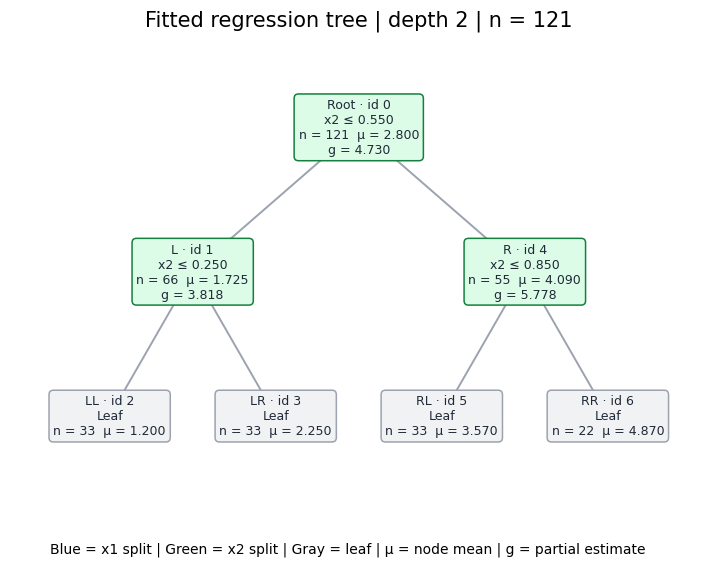

uniform


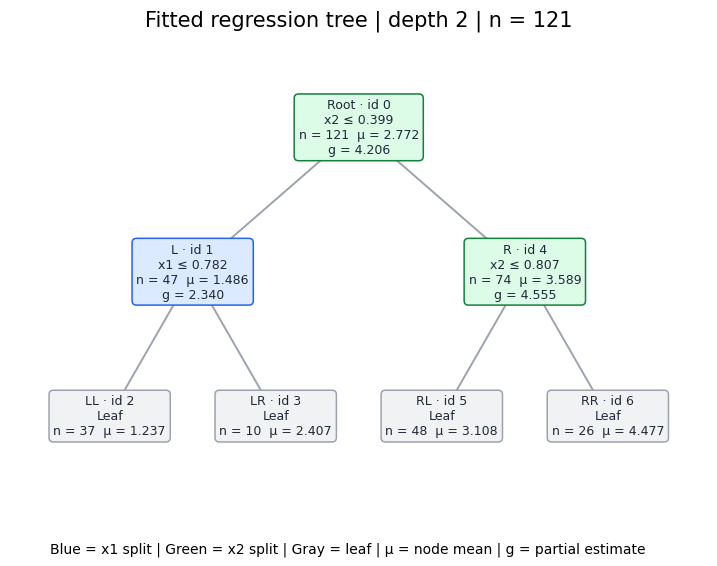

correlated


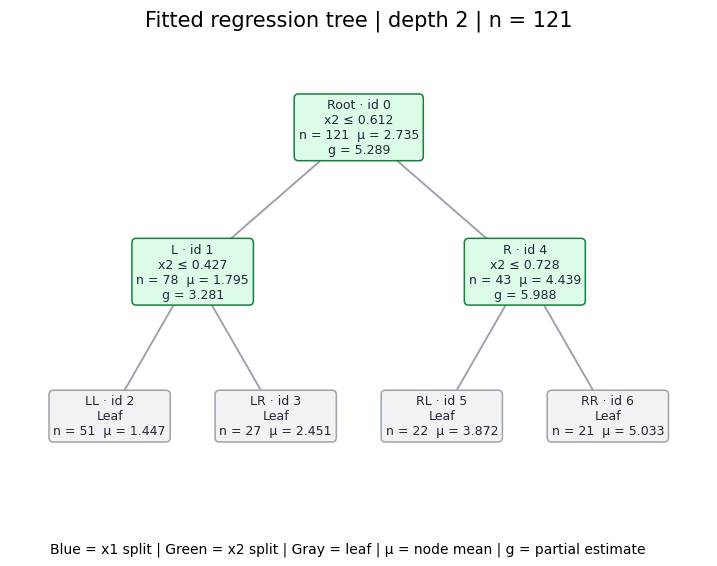

In [2]:
def plot_fitted_tree(tree):
    d = tree.get_depth()
    fig,ax = plt.subplots(figsize=(max(9,1.9*2**d),2*(d+1)))
    def draw(path,lo,hi,level,parent=None):
        v = node_info(tree,path)
        x,y = (lo+hi)/2,-level
        if parent is not None:
            ax.plot([parent[0],x],[parent[1],y],color='#9ca3af',lw=1.4,zorder=1)
        label = f"{path or 'Root'} · id {v['id']}\n"
        if v['axis'] < 0:
            label += f"Leaf\nn = {v['n']}  μ = {v['mean']:.3f}"
            fc,ec = '#f1f2f4','#9ca3af'
        else:
            label += f"x{v['axis']+1} ≤ {v['tau']:.3f}\nn = {v['n']}  μ = {v['mean']:.3f}\ng = {v['g']:.3f}"
            fc,ec = ('#dbeafe','#2563eb') if v['axis']==0 else ('#dcfce7','#15803d')
            draw(path+'L',lo,x,level+1,(x,y))
            draw(path+'R',x,hi,level+1,(x,y))
        ax.text(x,y,label,ha='center',va='center',fontsize=9,color='#1f2937',zorder=2,
                bbox=dict(boxstyle='round,pad=.35',fc=fc,ec=ec,lw=1.1))
    draw('',0,1,0)
    ax.set(xlim=(-.025,1.025),ylim=(-d-.55,.65))
    ax.axis('off')
    ax.set_title(f'Fitted regression tree | depth {d} | n = {tree.tree_.n_node_samples[0]}',fontsize=15)
    fig.text(.5,.015,'Blue = x1 split | Green = x2 split | Gray = leaf | μ = node mean | g = partial estimate',ha='center',fontsize=10)
    plt.show()

def make_data(n,seed,design='uniform'):
    rng=np.random.default_rng(seed)
    Z=rng.uniform(0,1,(n,2))
    if design=='correlated':
        Z[:,1]=0.65*Z[:,0]+0.35*Z[:,1]
    return Z
X_grid=X.copy()
for label,Z in [('grid',X_grid),('uniform',make_data(121,44)),('correlated',make_data(121,44,'correlated'))]:
    print(label)
    plot_fitted_tree(fit_tree(2,Z,f(*Z.T)))

## Moment identity (diagnostic, not an oracle estimator)
For a split on coordinate $s$ and other coordinate $j$, define $\Delta h$ as the right-minus-left empirical average of $h(X)$. Let $d=\Delta X_s>0$. Set $m_{s,e}=\Delta X_s^2/(2d)$ and retain the *geometric* midpoint $m_j$ of the nonsplit axis. This keeps the nonsplit coordinate fixed for the original eligible diagonal pairs. The empirical gradient is $g_e=\Delta Y/d$. The exact noiseless quadratic identity is

$$g_e= b_s+H_{ss}m_{s,e}+H_{sj}m_j + \frac{b_j\Delta X_j + \tfrac12 H_{jj}\Delta X_j^2 + H_{sj}(\Delta(X_sX_j)-m_j d)}{d}.$$

The last three terms separate nuisance drift in the nonsplit first moment, second moment and interaction moment. They vanish on the depth-2 balanced product grid, but not necessarily on a random or correlated design. On deeper grid boxes the geometric nonsplit midpoint can differ from the actual nonsplit mean. We keep this choice explicit for matched diagonal comparisons. The residual identity uses the known coefficients only to explain error, not to construct an estimator.

## 3. Empirical moments from the actual child observations

**Why:** Extract child membership, calculate the two proposed adjustments and verify the algebraic source of remaining error for either splitting axis.

In [3]:
b_true=np.array([-1.,2.])
def empirical_nodes(tree,Z):
    nodes=internal_nodes(tree)
    t=tree.tree_
    membership=tree.decision_path(Z).toarray().astype(bool)
    for v in nodes.values():
        s=v['axis']; j=1-s
        XL=Z[membership[:,t.children_left[v['id']]]]
        XR=Z[membership[:,t.children_right[v['id']]]]
        d=XR.mean(0)-XL.mean(0)
        d2=(XR**2).mean(0)-(XL**2).mean(0)
        cross=(XR[:,0]*XR[:,1]).mean()-(XL[:,0]*XL[:,1]).mean()
        assert d[s]>0
        m_emp=v['m'].copy(); m_emp[s]=d2[s]/(2*d[s])
        ge=(v['mean_right']-v['mean_left'])/d[s]
        terms=np.array([b_true[j]*d[j], 0.5*H_true[j,j]*d2[j], H_true[s,j]*(cross-v['m'][j]*d[s])])/d[s]
        truth_g=b_true[s]+H_true[s]@m_emp
        assert np.isclose(ge-truth_g,terms.sum(),atol=1e-9,rtol=0)
        v.update(dx=d[s],g_emp=ge,m_emp=m_emp,terms=terms,
                 original_error=v['g']-(b_true[s]+H_true[s]@v['m']),
                 empirical_error=ge-truth_g)
    return nodes
for label,Z in [('grid',X_grid),('uniform',make_data(121,44)),('correlated',make_data(121,44,'correlated'))]:
    print('\n',label,'(residual terms: first, second, interaction)')
    for path,v in empirical_nodes(fit_tree(2,Z,f(*Z.T)),Z).items():
        print(f"{path or 'Root':4} axis={v['axis']} g0={v['g']:.4f} ge={v['g_emp']:.4f} residual={v['empirical_error']:.4f} terms={np.round(v['terms'],4)}")


 grid (residual terms: first, second, interaction)
Root axis=1 g0=4.7300 ge=4.3000 residual=0.0000 terms=[-0.  0.  0.]
L    axis=1 g0=3.8182 ge=3.5000 residual=-0.0000 terms=[-0.  0. -0.]
R    axis=1 g0=5.7778 ge=5.2000 residual=0.0000 terms=[-0. -0. -0.]

 uniform (residual terms: first, second, interaction)
Root axis=1 g0=4.2061 ge=4.1837 residual=0.0160 terms=[-0.0202  0.0671 -0.031 ]
L    axis=0 g0=2.3405 ge=2.1958 residual=0.5103 terms=[0.2612 0.0686 0.1805]
R    axis=1 g0=4.5546 ge=5.0130 residual=0.0611 terms=[-0.0074  0.001   0.0675]

 correlated (residual terms: first, second, interaction)
Root axis=1 g0=5.2889 ge=7.0906 residual=2.7279 terms=[-1.3567  2.9224  1.1622]
L    axis=1 g0=3.2815 ge=4.7484 residual=0.8489 terms=[-1.0956  1.5583  0.3862]
R    axis=1 g0=5.9885 ge=8.2525 residual=3.2633 terms=[-0.8407  2.6892  1.4148]


## 4. Matched diagonal contrasts

**Why:** Hold the tree and pair selection fixed across the three methods. Restrict to direct local diagonal pairs: no corrected mixed terms or new solver. Reject nearly vanishing denominators in either geometry and report exclusions.

In [4]:
def diagonal_contrasts(tree,Z):
    nodes=empirical_nodes(tree,Z)
    out=[]; skipped=0
    for e,p,q,_,_ in eligible_pairs(tree,'local'):
        if e not in ('H11','H22'): continue
        a,b=nodes[p],nodes[q]; j=a['axis']
        d0=b['m'][j]-a['m'][j]; de=b['m_emp'][j]-a['m_emp'][j]
        if min(abs(d0),abs(de))<=1e-8:
            skipped+=1; continue
        vals=np.array([(b['g']-a['g'])/d0,(b['g_emp']-a['g_emp'])/d0,(b['g_emp']-a['g_emp'])/de])
        out.append((e,p,q,vals,abs(d0)))
    return out,skipped
for label,Z in [('grid',X_grid),('uniform',make_data(121,44)),('correlated',make_data(121,44,'correlated'))]:
    tree=fit_tree(2,Z,f(*Z.T)); rows,skipped=diagonal_contrasts(tree,Z)
    print('\n',label,'[original, spacing, spacing+location]')
    for e,p,q,vals,d in rows: print(e,p or 'Root',q or 'Root',np.round(vals,6))
    print('excluded:',skipped)
    if label=='grid': assert all(np.isclose(vals[2],3,atol=1e-10) for e,p,q,vals,d in rows)


 grid [original, spacing, spacing+location]
H22 Root L [3.647273 3.2      3.      ]
H22 Root R [3.69804  3.176471 3.      ]
H22 L R [3.674243 3.1875   3.      ]
excluded: 0

 uniform [original, spacing, spacing+location]
H22 Root R [1.294925 3.081094 3.172783]
excluded: 0

 correlated [original, spacing, spacing+location]
H22 Root L [10.504794 12.256757 15.16784 ]
H22 Root R [2.884839 4.791169 5.563655]
H22 L R [6.243112 8.08141  9.646431]
excluded: 0


## 5. Repeated sampling: do the adjustments help?

**Why:** Twenty reproducible seeds per design/sample-size/depth combination. Use the per-tree mean absolute error over matched individual diagonal contrasts, then average across nonempty trees; a busy tree does not dominate. Capture median leaf count and box diameter to inspect the joint size requirement.

In [5]:

def leaf_stats(tree):
    leaves=[]
    def visit(path):
        v=node_info(tree,path)
        if v['axis']<0:
            B=np.array(v['bounds']); leaves.append((v['n'],np.linalg.norm(B[1::2]-B[::2])))
        else:
            visit(path+'L'); visit(path+'R')
    visit(''); return np.median(np.array(leaves),axis=0)

def tree_diagonal_metrics(tree,Z):
    rows,skipped=diagonal_contrasts(tree,Z)
    if not rows: return None,skipped
    errs=np.array([abs(vals-H_true[int(e[-1])-1,int(e[-1])-1]) for e,p,q,vals,d in rows])
    return errs.mean(0),skipped
configs=[('uniform',n,d) for n in (121,1089,9801) for d in (2,4,6)]+[('correlated',1089,d) for d in (2,4,6)]
R=20
study={}; sample_trees={}
for design,n,d in configs:
    errors=[]; leaf=[]; excluded=0; wins=[]
    group=[]
    for seed in range(R):
        Z=make_data(n,seed,design); tree=fit_tree(d,Z,f(*Z.T)); group.append((Z,tree))
        err,skipped=tree_diagonal_metrics(tree,Z); excluded+=skipped; leaf.append(leaf_stats(tree))
        if err is not None: errors.append(err); wins.append(err[2]<err[0])
    sample_trees[design,n,d]=group
    errs=np.array(errors)
    study[design,n,d]=(len(errs),errs.mean(0) if len(errs) else np.full(3,np.nan),np.median(leaf,0),np.mean(wins) if wins else np.nan,excluded)
print('design       n depth used     MAE original   spacing    both    win%  leaf n  diameter  excluded')
for (design,n,d),(used,err,leaf,win,exc) in study.items():
    print(f'{design:11} {n:5} {d:3} {used:3}/{R} {err[0]:14.5f} {err[1]:9.5f} {err[2]:9.5f} {100*win:7.1f} {leaf[0]:7.1f} {leaf[1]:9.4f} {exc:6}')

design       n depth used     MAE original   spacing    both    win%  leaf n  diameter  excluded
uniform       121   2  20/20        1.94129   1.43440   1.39696    65.0    31.0    0.9589      0
uniform       121   4  20/20        3.94589   5.13262   5.30461    50.0     7.0    0.4396      0
uniform       121   6  20/20        8.71476   9.59768  10.24665    45.0     5.0    0.3777      0
uniform      1089   2  20/20        0.62111   0.49685   0.50406    70.0   269.2    0.9683      0
uniform      1089   4  20/20        1.66676   1.42186   1.41751    75.0    62.0    0.4221      0
uniform      1089   6  20/20        7.82362   7.72782   7.76874    55.0    14.0    0.1921      0
uniform      9801   2  20/20        0.20235   0.16970   0.16592    65.0  2488.5    1.0294      0
uniform      9801   4  20/20        0.49729   0.38290   0.37982    65.0   530.5    0.4064      0
uniform      9801   6  20/20        2.60376   2.17940   2.15749    65.0   125.5    0.1941      0
correlated   1089   2  20/20  

## 6. Visual comparison

**Why:** See the error trade-off across sample sizes and depths; the estimators are compared on the same eligible pairs.

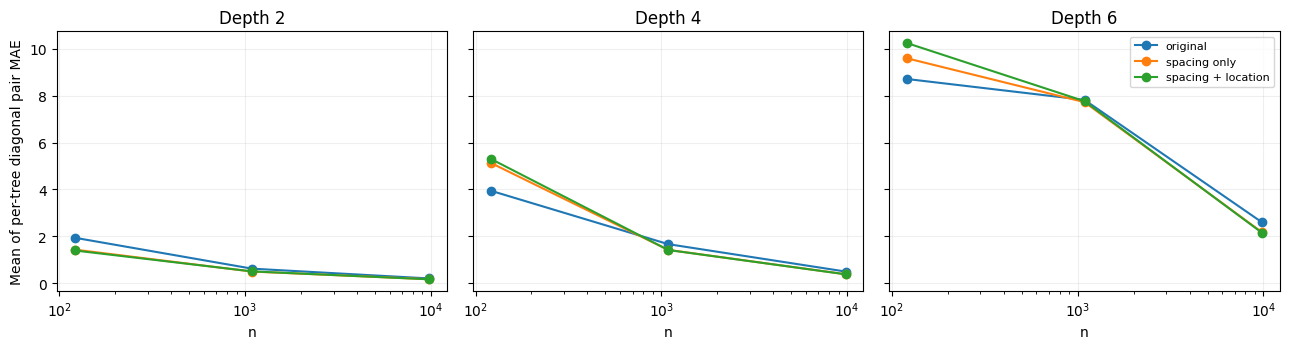

In [6]:
fig,axes=plt.subplots(1,3,figsize=(13,3.6),sharey=True)
for ax,d in zip(axes,(2,4,6)):
    ns=[121,1089,9801]
    for k,label in enumerate(('original','spacing only','spacing + location')):
        ax.plot(ns,[study['uniform',n,d][1][k] for n in ns],marker='o',label=label)
    ax.set_xscale('log');ax.set_title(f'Depth {d}');ax.set_xlabel('n');ax.grid(alpha=.2)
axes[0].set_ylabel('Mean of per-tree diagonal pair MAE');axes[-1].legend(fontsize=8);fig.tight_layout();plt.show()

## 7. Direct-case availability

**Why:** Measure all four entries separately using the original geometric definition; distinguish number of candidates from probability of having at least one candidate. Do not treat missing as zero.

In [7]:
entries=['H11','H12','H21','H22']
def count_hessian_cases(tree,mode='all'):
    counts=dict.fromkeys(entries,0)
    for e,*_ in eligible_pairs(tree,mode): counts[e]+=1
    return counts
print('design n depth mode | mean counts [11,12,21,22] | coverage % [11,12,21,22] | all four %')
for (design,n,d),group in sample_trees.items():
    for mode in ('local','all'):
        counts=np.array([[count_hessian_cases(t,mode)[e] for e in entries] for _,t in group])
        print(design,n,d,mode,'|',np.round(counts.mean(0),2),'|',np.round(100*(counts>0).mean(0),1),'|',100*np.all(counts>0,axis=1).mean())

design n depth mode | mean counts [11,12,21,22] | coverage % [11,12,21,22] | all four %
uniform 121 2 local | [0.  0.  0.  1.9] | [  0.   0.   0. 100.] | 0.0
uniform 121 2 all | [0.  0.  0.  1.9] | [  0.   0.   0. 100.] | 0.0
uniform 121 4 local | [1.15 0.   0.   2.85] | [ 70.   0.   0. 100.] | 0.0
uniform 121 4 all | [1.15 0.   0.   3.  ] | [ 70.   0.   0. 100.] | 0.0
uniform 121 6 local | [2.05 0.   0.   5.55] | [ 75.   0.   0. 100.] | 0.0
uniform 121 6 all | [2.15 0.   0.   6.7 ] | [ 75.   0.   0. 100.] | 0.0
uniform 1089 2 local | [0. 0. 0. 2.] | [  0.   0.   0. 100.] | 0.0
uniform 1089 2 all | [0. 0. 0. 2.] | [  0.   0.   0. 100.] | 0.0
uniform 1089 4 local | [1.15 0.   0.   3.15] | [ 65.   0.   0. 100.] | 0.0
uniform 1089 4 all | [1.15 0.   0.   3.15] | [ 65.   0.   0. 100.] | 0.0


uniform 1089 6 local | [8.15 0.   0.   9.35] | [100.   0.   0. 100.] | 0.0
uniform 1089 6 all | [8.15 0.   0.   9.5 ] | [100.   0.   0. 100.] | 0.0
uniform 9801 2 local | [0.  0.  0.  2.4] | [  0.   0.   0. 100.] | 0.0
uniform 9801 2 all | [0.  0.  0.  2.4] | [  0.   0.   0. 100.] | 0.0


uniform 9801 4 local | [1.3  0.   0.   3.15] | [ 70.   0.   0. 100.] | 0.0
uniform 9801 4 all | [1.3  0.   0.   3.15] | [ 70.   0.   0. 100.] | 0.0
uniform 9801 6 local | [5.15 0.   0.   7.25] | [ 95.   0.   0. 100.] | 0.0


uniform 9801 6 all | [5.15 0.   0.   7.25] | [ 95.   0.   0. 100.] | 0.0
correlated 1089 2 local | [0. 0. 0. 3.] | [  0.   0.   0. 100.] | 0.0
correlated 1089 2 all | [0. 0. 0. 3.] | [  0.   0.   0. 100.] | 0.0
correlated 1089 4 local | [1.5 0.  0.  8.5] | [ 85.   0.   0. 100.] | 0.0
correlated 1089 4 all | [ 1.5  0.   0.  24. ] | [ 85.   0.   0. 100.] | 0.0
correlated 1089 6 local | [10.95  0.    0.   24.45] | [100.   0.   0. 100.] | 0.0


correlated 1089 6 all | [ 12.85   0.     0.   107.8 ] | [100.   0.   0. 100.] | 0.0


## 8. Aggregation: compare equal and separation-weighted averages

**Why:** Use original direct diagonal estimates only; weights are geometric separation (heuristic), not claimed optimal or inverse-variance. Measure tree-level entry errors for each method on common support. Compare local vs all directly eligible pairs.

In [8]:
def collect_direct(tree,mode):
    out={e:[] for e in entries}
    for e,p,q,a,b in eligible_pairs(tree,mode):
        j=int(e[-1])-1; dm=b['m'][j]-a['m'][j]
        out[e].append(((b['g']-a['g'])/dm,abs(dm)))
    return out

def pooled(rows,weighted=False):
    if not rows: return np.nan
    arr=np.array(rows)
    return np.average(arr[:,0],weights=arr[:,1]) if weighted else arr[:,0].mean()

print('design n depth usable tree-entries | MAE local mean / all mean / all distance-weighted')
for (design,n,d),group in sample_trees.items():
    per_tree=[]; usable=0
    for Z,tree in group:
        L=collect_direct(tree,'local'); A=collect_direct(tree,'all')
        errs=[]
        for e in ('H11','H22'):
            if not L[e]:continue
            truth=H_true[int(e[-1])-1,int(e[-1])-1]
            errs.append(np.abs(np.array([pooled(L[e]),pooled(A[e]),pooled(A[e],True)])-truth));usable+=1
        if errs: per_tree.append(np.mean(errs,axis=0))
    print(design,n,d,usable,'|',np.round(np.mean(per_tree,axis=0),5) if per_tree else 'unavailable')

design n depth usable tree-entries | MAE local mean / all mean / all distance-weighted
uniform 121 2 20 | [1.70737 1.70737 1.72341]
uniform 121 4 34 | [3.16598 3.08846 2.64924]
uniform 121 6 35 | [5.98815 6.16554 4.22342]
uniform 1089 2 20 | [0.49948 0.49948 0.50084]
uniform 1089 4 33 | [1.25122 1.25122 1.04749]
uniform 1089 6 40 | [3.73622 3.68071 2.22245]
uniform 9801 2 20 | [0.17543 0.17543 0.17656]
uniform 9801 4 34 | [0.44439 0.44439 0.38732]


uniform 9801 6 39 | [1.41153 1.41153 0.71048]
correlated 1089 2 20 | [3.58496 3.58496 3.65437]
correlated 1089 4 37 | [4.25791 4.9598  3.45461]
correlated 1089 6 40 | [4.30874 4.86155 3.01739]


## 9. Corrected sibling mixed partials and symmetry

**Why:** Test the existing mixed correction (using the original all-pair diagonal average) on sibling nodes with the same derivative axis and distinct nonsplit locations. Keep H12/H21 separate and report full-matrix availability before assessing Frobenius error. This does not test empirical-moment mixed corrections.

In [9]:
def corrected_matrix(tree):
    nd=internal_nodes(tree); direct=collect_direct(tree,'all')
    H=np.array([[pooled(direct['H11']),np.nan],[np.nan,pooled(direct['H22'])]])
    mixed={0:[],1:[]}
    for p in nd:
        l,r=p+'L',p+'R'
        if l not in nd or r not in nd:continue
        a,b=nd[l],nd[r]; s=a['axis']; j=1-s
        if b['axis']!=s:continue
        dm=b['m']-a['m']
        if abs(dm[j])<=1e-8:continue
        if abs(dm[s])<=1e-8: mixed[s].append((b['g']-a['g'])/dm[j])
        elif np.isfinite(H[s,s]):mixed[s].append((b['g']-a['g']-H[s,s]*dm[s])/dm[j])
    for s in (0,1):
        if mixed[s]:H[s,1-s]=np.mean(mixed[s])
    return H, [len(mixed[0]),len(mixed[1])]
print('design n depth | mixed coverage 12/21 % | full /20 | mean Frobenius error copy / independent / symmetric')
for (design,n,d),group in sample_trees.items():
    coverage=[]; errors=[]
    for _,tree in group:
        B,c=corrected_matrix(tree);coverage.append(np.array(c)>0)
        if np.all(np.isfinite(B)):
            A=B.copy();A[1,0]=A[0,1]; C=(B+B.T)/2
            vals=[np.linalg.norm(H-H_true,'fro') for H in (A,B,C)]
            assert vals[2]<=vals[1]+1e-10
            errors.append(vals)
    print(design,n,d,'|',np.round(100*np.mean(coverage,axis=0),1),'|',len(errors),'|',np.round(np.mean(errors,axis=0),5) if errors else 'unavailable')

design n depth | mixed coverage 12/21 % | full /20 | mean Frobenius error copy / independent / symmetric
uniform 121 2 | [0. 0.] | 0 | unavailable
uniform 121 4 | [70. 95.] | 13 | [4.44361 4.61584 4.30882]
uniform 121 6 | [75. 95.] | 14 | [9.27062 9.30979 9.16167]
uniform 1089 2 | [0. 0.] | 0 | unavailable
uniform 1089 4 | [ 65. 100.] | 13 | [1.75874 1.81088 1.70443]


uniform 1089 6 | [100. 100.] | 20 | [6.53765 6.45972 6.30219]
uniform 9801 2 | [0. 0.] | 0 | unavailable
uniform 9801 4 | [ 70. 100.] | 14 | [0.52977 0.53189 0.49305]
uniform 9801 6 | [ 95. 100.] | 19 | [2.47139 2.51061 2.48595]
correlated 1089 2 | [0. 0.] | 0 | unavailable
correlated 1089 4 | [45. 70.] | 6 | [7.43774 6.99977 6.70025]
correlated 1089 6 | [100. 100.] | 20 | [9.5155  9.65692 9.20652]


## Review before claiming a result
- Exact continuous means were an oracle control, not an adjustment to sklearn response means. Here the empirical gradient candidate changes only spacing and split-axis location.
- Repeated experiments are exploratory (20 seeds per design/configuration), noiseless, and use the same constant Hessian. Correlated samples have restricted support. Box diameters are geometric, not observed support diameters. The moment residual identity is exact for this quadratic; a useful general correction is not yet derived.
- Direct pair coverage is stricter than correction-based availability: neither proves identifiability by other methods. Direct pairs share nodes and are not independent.
- Symmetry comparisons condition on having all four raw entries; this selected subset is not representative of all trees. Missing entries remain NaN.
- Examine the tables first. Decide whether more evidence supports improving the first-derivative estimator, designing more reliable local comparisons, or aggregation. Do not claim consistency, unbiasedness, or a solution for arbitrary functions.

## Interpretation of the executed run (review notes, not new experiments)

| Question | Observed evidence | Decision / limit |
|---|---|---|
| Does empirical spacing + location help? | On the grid all 3 H22 contrasts recover 3. For uniform n=1089, depth 4, mean per-tree diagonal-pair MAE falls 1.66676 → 1.41751; 15/20 trees improve. For correlated n=1089, depth 2, MAE rises 3.58496 → 6.09902; 0/20 improve. | Keep as an experimental variant; do not replace the baseline. |
| Why can it fail? | The actual child moment contrasts on the correlated seed-44 root give nonzero nuisance first-, second- and interaction-moment terms (-1.3567, 2.9224, 1.1622), summing to 2.7279 in the empirical gradient. | The empirical adjustment corrects split-axis geometry, not shifts in the other coordinate. |
| Does more depth help? | Uniform n=9801: original individual-pair MAE 0.20235, 0.49729, 2.60376 at depths 2,4,6, while median geometric leaf diameter shrinks 1.0294 → 0.4064 → 0.1941. With n=121,1089,9801 and depths 2,4,6 together, median leaf sample counts grow 31 → 62 → 125.5 but individual-pair MAE is 1.94129 → 1.66676 → 2.60376. | The finite-sample results do not prove or disprove consistency; the gradient error is amplified by small effective-location separations. |
| Does averaging help? | At uniform n=9801, depth 6, per-tree mean of diagonal-entry errors is 1.41153 (local or all equal weights) vs 0.71048 (all separation-weighted). At depth 2 separation weights slightly worsen the equal-weight result. | Separation weighting is a heuristic to test, not an optimality claim. |
| Are mixed entries available? | No direct mixed-partial comparisons across these 240 fitted trees using the geometric alignment tolerance. With original correction-based siblings, full four-entry matrices are available on 13/20 at uniform n=1089 depth 4 and 20/20 at depth 6. | Preserve direct counts and correction-based counts separately; never fill unavailable entries with zero. |
| Should we enforce symmetry? | For uniform n=9801, depth 4, conditional on 14/20 complete matrices, mean Frobenius error is 0.52977 (copy H12), 0.53189 (independent), 0.49305 (symmetric mean). | Keep independent estimates for diagnostics. Projection reduces Frobenius error relative to the independent matrix by construction, not empirical proof of estimator superiority. |

**Recommended discussion:** Start with the depth-2 seed-44 examples and the exact moment identity, then ask whether we can control nonsplit-coordinate moment differences (e.g., matching or reweighting children) without relying on unknown derivatives. This is a possible direction, not a validated method. Compare any proposed fix with the unchanged estimator on matched nodes. Only then decide which aggregation weights to pursue.

**Design limitations:** Twenty seeds per configuration; the same seeds are reused across depths for comparability. The 240 fits are not independent of one another across configurations. No response noise, no nonquadratic targets, no real-data truth, and no formal uncertainty or consistency analysis. The correlated design restricts the joint support; it is a deliberate stress test, not a model of a particular real dataset. No claim that the empirical moment variant works for all Hessian entries; the matched experiment uses diagonal comparisons only. Mixed corrections use the original geometric quantities.